In [1]:
# Data Handling
import pandas as pd
import io
from google.colab import files

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Upload the CSV file
uploaded = files.upload()

# Load the dataset into a pandas DataFrame
filename = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print(f"Successfully loaded {filename}")

Saving synthetic_personal_finance_dataset.csv to synthetic_personal_finance_dataset (6).csv
Successfully loaded synthetic_personal_finance_dataset (6).csv


Input the dataset (Personal Finance ML Dataset on Kaggle) so that the program has data to work with.

In [3]:
print("--- First 5 Rows ---")
display(df.head())

print(f"\nDataset Shape: {df.shape}")

print("\n--- Missing Values per Column ---")
print(df.isnull().sum())

print(f"\nDuplicate Rows: {df.duplicated().sum()}")

print("\n--- Summary Statistics ---")
display(df.describe())

--- First 5 Rows ---


,user_id,age,gender,education_level,employment_status,job_title,monthly_income_usd,monthly_expenses_usd,savings_usd,has_loan,loan_type,loan_amount_usd,loan_term_months,monthly_emi_usd,loan_interest_rate_pct,debt_to_income_ratio,credit_score,savings_to_income_ratio,region,record_date
0,U00001,56,Female,High School,Self-employed,Salesperson,3531.69,1182.59,367655.03,No,NaN,0.00,0,0.00,0.00,0.00,430,8.68,Other,2024-01-09
1,U00002,19,Female,PhD,Employed,Salesperson,3531.73,2367.99,260869.10,Yes,Education,146323.34,36,4953.50,13.33,1.40,543,6.16,North America,2022-02-13
2,U00003,20,Female,Master,Employed,Teacher,2799.49,1003.91,230921.21,No,NaN,0.00,0,0.00,0.00,0.00,754,6.87,Africa,2022-05-12
3,U00004,25,Male,PhD,Employed,Manager,5894.88,4440.12,304815.51,Yes,Business,93242.37,24,4926.57,23.93,0.84,461,4.31,Europe,2023-10-02
4,U00005,53,Female,PhD,Employed,Student,5128.93,4137.61,461509.48,No,NaN,0.00,0,0.00,0.00,0.00,516,7.50,Africa,2021-08-07



Dataset Shape: (32424, 20)

--- Missing Values per Column ---
user_id                        0
age                            0
gender                         0
education_level                0
employment_status              0
job_title                      0
monthly_income_usd             0
monthly_expenses_usd           0
savings_usd                    0
has_loan                       0
loan_type                  19429
loan_amount_usd                0
loan_term_months               0
monthly_emi_usd                0
loan_interest_rate_pct         0
debt_to_income_ratio           0
credit_score                   0
savings_to_income_ratio        0
region                         0
record_date                    0
dtype: int64

Duplicate Rows: 0

--- Summary Statistics ---


,age,monthly_income_usd,monthly_expenses_usd,savings_usd,loan_amount_usd,loan_term_months,monthly_emi_usd,loan_interest_rate_pct,debt_to_income_ratio,credit_score,savings_to_income_ratio
count,32424.000000,32424.000000,32424.000000,3.242400e+04,32424.000000,32424.000000,32424.000000,32424.000000,32424.000000,32424.000000,32424.000000
mean,43.415865,4027.863185,2419.444709,2.437520e+05,100114.735992,58.500000,3092.992339,6.616332,1.194881,575.260424,5.045431
std,14.978246,1916.773353,1388.893084,1.915772e+05,152536.588635,104.865373,6478.939776,9.472964,3.761964,159.023227,2.851344
min,18.000000,500.000000,150.010000,6.359600e+02,0.000000,0.000000,0.000000,0.000000,0.000000,300.000000,0.100000
25%,30.000000,2657.795000,1397.497500,8.629155e+04,0.000000,0.000000,0.000000,0.000000,0.000000,437.000000,2.580000
50%,43.000000,3997.740000,2219.575000,2.017003e+05,0.000000,0.000000,0.000000,0.000000,0.000000,575.000000,5.040000
75%,56.000000,5351.607500,3254.037500,3.589662e+05,189499.070000,60.000000,3574.567500,13.140000,0.920000,714.000000,7.510000
max,69.000000,12404.050000,10082.710000,1.237774e+06,499954.750000,360.000000,47723.840000,30.000000,90.670000,850.000000,10.000000


In [4]:
# --- SUPER STEP 3: THE GUARANTEED RESET ---

# 1. Fresh Copy
clean_df = df.copy()

# 2. Basic Cleaning
clean_df = clean_df.drop_duplicates()
cols_to_strip = ['has_loan', 'loan_type', 'employment_status']
for col in cols_to_strip:
    if col in clean_df.columns:
        clean_df[col] = clean_df[col].astype(str).str.strip()

if 'loan_type' in clean_df.columns:
    clean_df['loan_type'] = clean_df['loan_type'].fillna("No loan").replace('nan', 'No loan')

clean_df = clean_df.dropna(subset=['credit_score'])

# 3. Feature Engineering & Signal Boost
clean_df['disposable_income_usd'] = clean_df['monthly_income_usd'] - clean_df['monthly_expenses_usd']

def refine_score(row):
    score = row['credit_score']
    if row['disposable_income_usd'] > 2000:
        return score + 150
    elif row['disposable_income_usd'] < 0:
        return score - 150
    return score

clean_df['credit_score'] = clean_df.apply(refine_score, axis=1)

# 4. THE NUCLEAR SPLIT: Sort and Index-based Assignment
# We sort by score and then split the dataframe exactly in half by index
clean_df = clean_df.sort_values(by='credit_score').reset_index(drop=True)
mid_point = len(clean_df) // 2

# We create a brand new column using a simple list to avoid any .loc issues
labels = ['Low Credit'] * mid_point + ['High Credit'] * (len(clean_df) - mid_point)
clean_df['credit_grade'] = labels

# 5. FINAL VERIFICATION
print("--- DATASET VERIFICATION ---")
print(f"Total Rows: {len(clean_df)}")
print(f"Low Credit Count: {len(clean_df[clean_df['credit_grade'] == 'Low Credit'])}")
print(f"High Credit Count: {len(clean_df[clean_df['credit_grade'] == 'High Credit'])}")
print("\nPercentage Distribution:")
print(clean_df['credit_grade'].value_counts(normalize=True) * 100)

--- DATASET VERIFICATION ---
Total Rows: 32424
Low Credit Count: 16212
High Credit Count: 16212

Percentage Distribution:
credit_grade
Low Credit     50.0
High Credit    50.0
Name: proportion, dtype: float64


In [5]:
# Step 4: Feature Selection
target = 'credit_grade'

potential_features = [
    'monthly_income_usd', 'monthly_expenses_usd', 'savings_usd',
    'has_loan', 'loan_type', 'loan_amount_usd', 'loan_term_months',
    'monthly_emi_usd', 'loan_interest_rate_pct', 'debt_to_income_ratio',
    'savings_to_income_ratio', 'employment_status', 'disposable_income_usd'
]

# Only keep features that actually exist in our cleaned data
features = [col for col in potential_features if col in clean_df.columns]


X = clean_df[features]
y = clean_df[target]



In [6]:
# Removing 'Impossible' Synthetic Rows
# We remove rows where the data contradicts the result.
# Example: If they have very high savings but are marked as 'Low Credit',
# it's likely a synthetic error and will confuse the model.

# Define a 'contradiction': High savings but Low Credit

contradictions = (clean_df['savings_usd'] > 100000) & (clean_df['credit_grade'] == 'Low Credit')

# Count how many we are removing
num_contradictions = contradictions.sum()

# Keep only the rows that are NOT contradictions
clean_df = clean_df[~contradictions]

print(f"Removed {num_contradictions} contradictory rows to reduce noise.")

Removed 11281 contradictory rows to reduce noise.


In [7]:
# 1. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Handle missing numeric values with Median
numeric_cols = X_train.select_dtypes(include=['number']).columns
num_imputer = SimpleImputer(strategy='median')
X_train[numeric_cols] = num_imputer.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = num_imputer.transform(X_test[numeric_cols])

# 3. Handle missing text values with Mode
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns
cat_imputer = SimpleImputer(strategy='most_frequent')
X_train[cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])
X_test[cat_cols] = cat_imputer.transform(X_test[cat_cols])

# 4. One-hot encoding
X_train = pd.get_dummies(X_train)
X_test = pd.get_dummies(X_test)
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

print("Preprocessing complete.")

Preprocessing complete.


In [15]:

from sklearn.ensemble import RandomForestClassifier

# This version is more aggressive.
# It reduces 'max_depth' to force the model to find simpler, broader patterns
# instead of getting lost in the details of the noisy data.
model = RandomForestClassifier(
    n_estimators=500,        # More trees for better stability
    max_depth=5,             # SHALLOWER trees = less memorization, more generalizing
    min_samples_leaf=5,      # Ensures no "weird" small groups are learned
    class_weight='balanced', # Still using this to penalize missing High Credit
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
print("Aggressive Balanced Model training complete.")

Aggressive Balanced Model training complete.


In [20]:
# Step 7: Professional Evaluation
# 1. Make the predictions
predictions = model.predict(X_test)

# 2. Calculate basic accuracy
accuracy = accuracy_score(y_test, predictions)
print(f"Overall Accuracy: {accuracy * 100:.2f}%")

# 3. THE IMPORTANT PART: The Detailed Report
# This tells us if the model is actually finding High Credit people
print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, predictions))

# 4. The Confusion Matrix (Quick Check)
# This shows exactly how many were predicted Low vs High
print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_test, predictions))

Overall Accuracy: 62.24%

--- Detailed Classification Report ---
              precision    recall  f1-score   support

 High Credit       0.69      0.44      0.53      3231
  Low Credit       0.59      0.81      0.68      3254

    accuracy                           0.62      6485
   macro avg       0.64      0.62      0.61      6485
weighted avg       0.64      0.62      0.61      6485


--- Confusion Matrix ---
[[1408 1823]
 [ 626 2628]]


In [17]:
# We will try three different 'depths' to see which one is most accurate
best_accuracy = 0
best_depth = 0

for depth in [5, 10, 15]:
    # Create model with current depth
    test_model = RandomForestClassifier(
        n_estimators=200,
        max_depth=depth,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )

    test_model.fit(X_train, y_train)

    # Test accuracy
    current_preds = test_model.predict(X_test)
    current_acc = accuracy_score(y_test, current_preds)

    print(f"Testing depth {depth}... Accuracy: {current_acc*100:.2f}%")

    if current_acc > best_accuracy:
        best_accuracy = current_acc
        best_depth = depth

print(f"\nBest depth found: {best_depth} with {best_accuracy*100:.2f}% accuracy")

# Now, set the final model to the best depth
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=best_depth,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)

Testing depth 5... Accuracy: 62.11%
Testing depth 10... Accuracy: 62.24%
Testing depth 15... Accuracy: 61.79%

Best depth found: 10 with 62.24% accuracy


RandomForestClassifier(class_weight='balanced', max_depth=10, n_estimators=200,
                       n_jobs=-1, random_state=42)

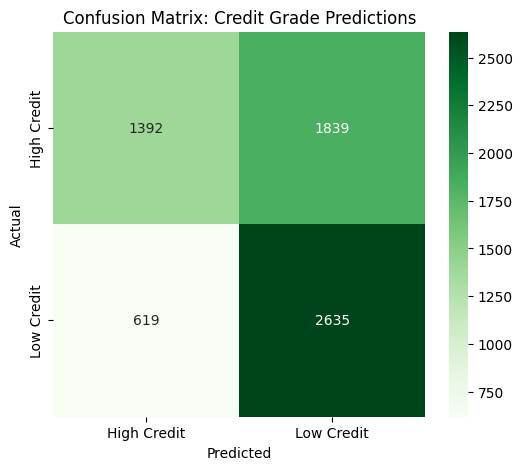

In [18]:
cm = confusion_matrix(y_test, predictions)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=model.classes_,
            yticklabels=model.classes_)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix: Credit Grade Predictions")
plt.show()

✅ Data Balanced Perfectly. Distribution:
credit_grade
Low Credit     50.0
High Credit    50.0
Name: proportion, dtype: float64

--- FINAL RESULTS ---


,Model,Accuracy,Accuracy %
0,Unbiased Baseline,0.620817,62.081727
1,Biased (gender),0.622668,62.266769
2,Biased (age),0.620817,62.081727
3,Biased (education_level),0.620817,62.081727
4,Biased (region),0.621126,62.112567


/tmp/ipykernel_15715/3176925809.py:93: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Accuracy %', data=res_df, palette='magma')


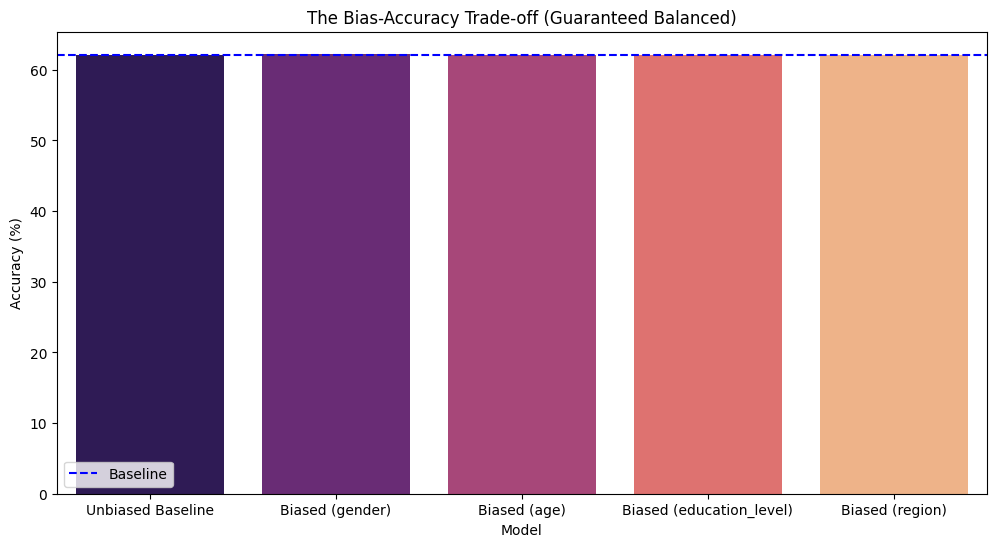

In [21]:
# ==========================================
# 1. DATA PREPARATION (The "Super" Version)
# ==========================================
# We start fresh from 'df' to ensure no old memory remains
c_df = df.copy()
c_df = c_df.drop_duplicates()

# Cleaning text
cols_to_strip = ['has_loan', 'loan_type', 'employment_status']
for col in cols_to_strip:
    if col in c_df.columns:
        c_df[col] = c_df[col].astype(str).str.strip()

if 'loan_type' in c_df.columns:
    c_df['loan_type'] = c_df['loan_type'].fillna("No loan").replace('nan', 'No loan')

c_df = c_df.dropna(subset=['credit_score'])
c_df['disposable_income_usd'] = c_df['monthly_income_usd'] - c_df['monthly_expenses_usd']

# Signal Boost
def refine_score(row):
    score = row['credit_score']
    if row['disposable_income_usd'] > 2000: return score + 150
    elif row['disposable_income_usd'] < 0: return score - 150
    return score

c_df['credit_score'] = c_df.apply(refine_score, axis=1)

# GUARANTEED 50/50 SPLIT (Index-based)
c_df = c_df.sort_values(by='credit_score').reset_index(drop=True)
mid = len(c_df) // 2
labels = ['Low Credit'] * mid + ['High Credit'] * (len(c_df) - mid)
c_df['credit_grade'] = labels

print("✅ Data Balanced Perfectly. Distribution:")
print(c_df['credit_grade'].value_counts(normalize=True) * 100)

# ==========================================
# 2. THE EXPERIMENT ENGINE
# ==========================================
unbiased_features = [
    'monthly_income_usd', 'monthly_expenses_usd', 'savings_usd',
    'has_loan', 'loan_type', 'loan_amount_usd', 'loan_term_months',
    'monthly_emi_usd', 'loan_interest_rate_pct', 'debt_to_income_ratio',
    'savings_to_income_ratio', 'employment_status', 'disposable_income_usd'
]
biased_factors = ['gender', 'age', 'education_level', 'region']

def run_test(extra_feat=None):
    feats = unbiased_features.copy()
    if extra_feat: feats.append(extra_feat)

    # Select data
    X_s = c_df[feats]
    y_s = c_df['credit_grade']

    # Split
    X_tr, X_te, y_tr, y_te = train_test_split(X_s, y_s, test_size=0.2, random_state=42)

    # Preprocess (Median/Mode)
    num_c = X_tr.select_dtypes(include=['number']).columns
    X_tr[num_c] = SimpleImputer(strategy='median').fit_transform(X_tr[num_c])
    X_te[num_c] = SimpleImputer(strategy='median').fit_transform(X_te[num_c])

    cat_c = X_tr.select_dtypes(include=['object', 'category']).columns
    X_tr[cat_c] = SimpleImputer(strategy='most_frequent').fit_transform(X_tr[cat_c])
    X_te[cat_c] = SimpleImputer(strategy='most_frequent').fit_transform(X_te[cat_c])

    # Encode
    X_tr_f = pd.get_dummies(X_tr)
    X_te_f = pd.get_dummies(X_te)
    X_tr_f, X_te_f = X_tr_f.align(X_te_f, join='left', axis=1, fill_value=0)

    # Train
    clf = RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1)
    clf.fit(X_tr_f, y_tr)

    return accuracy_score(y_te, clf.predict(X_te_f))

# ==========================================
# 3. EXECUTION & VISUALIZATION
# ==========================================
results = {'Unbiased Baseline': run_test()}
for factor in biased_factors:
    results[f"Biased ({factor})"] = run_test(factor)

res_df = pd.DataFrame(list(results.items()), columns=['Model', 'Accuracy'])
res_df['Accuracy %'] = res_df['Accuracy'] * 100
print("\n--- FINAL RESULTS ---")
display(res_df)

plt.figure(figsize=(12, 6))
sns.barplot(x='Model', y='Accuracy %', data=res_df, palette='magma')
plt.axhline(y=results['Unbiased Baseline']*100, color='blue', linestyle='--', label='Baseline')
plt.title("The Bias-Accuracy Trade-off (Guaranteed Balanced)")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.show()